In [1]:
readFile <- function(filename, separator, hasHeader) {
    read.table (file=filename,sep=separator, header=hasHeader)    
}

AttributsQuantitatives <- function(datasetFile, separator, hasHeader, indexTargetVariable, indexesQuantitativeColumns) {
    data <- readFile(datasetFile, separator, hasHeader)
    # Create empty slots for columns
    attributeNames <- c()
    averages <- c()
    variances <- c()
    condMeansNOTLEFT <- c()
    condMeansLEFT <- c()
    condVariaNOTLEFT <- c()
    condVariaLEFT <- c()
    importanceScores <- c()
    # Averages of attributes and variances
    for(index in indexesQuantitativeColumns) {
        avg <- mean(data[,index])
        variance <- var(data[,index])

        # Conditional averages
        condmean0 <- mean(data[data[,indexTargetVariable] == 0, index])
        condmean1 <- mean(data[data[,indexTargetVariable] == 1, index])

        # Conditional variances
        condvaria0 <- var(data[data[,indexTargetVariable] == 0, index])
        condvaria1 <- var(data[data[,indexTargetVariable] == 1, index])

        # Importance Score
        attributesScore<-abs(condmean0-condmean1)/sqrt(diag(var(data[,index, drop = FALSE])))
        
        # Storing the sorted values into the empty table
        attributeNames <- c(attributeNames, names(data)[index])
        averages <- c(averages, avg)
        variances <- c(variances, variance)
        condMeansNOTLEFT <- c(condMeansNOTLEFT, condmean0)
        condMeansLEFT <- c(condMeansLEFT, condmean1)
        condVariaNOTLEFT <- c(condVariaNOTLEFT, condvaria0)
        condVariaLEFT <- c(condVariaLEFT, condvaria1)
        importanceScores <- c(importanceScores, attributesScore)
        
    }

    # Create the table
    resultsTable <- data.frame(
    Attribut = attributeNames,
    Moyenne = averages,
    Variance = variances,
    Moyn_cond_classe_1 = condMeansNOTLEFT,
    Moyn_cond_classe_2 = condMeansLEFT,
    Vari_cond_classe_1 = condVariaNOTLEFT,
    Vari_cond_classe_2 = condVariaLEFT,
    Score_importance = importanceScores
    )

    resultsTable <- resultsTable[order(resultsTable$Score_importance, decreasing = TRUE),]
    print(resultsTable, row.names = FALSE)
}


AttributsQuantitatives("HR_prediction-all.csv", ",", TRUE, 8, c(2,3,4,5,6))
 

             Attribut    Moyenne     Variance Moyn_cond_classe_1
   satisfaction_level   0.613989 6.120140e-02          0.6672687
   time_spend_company   3.493900 2.137577e+00          3.3739336
 average_montly_hours 200.686300 2.484202e+03        198.7671610
       number_project   3.799000 1.515551e+00          3.7852737
      last_evaluation   0.717581 2.956431e-02          0.7173894
 Moyn_cond_classe_2 Vari_cond_classe_1 Vari_cond_classe_2 Score_importance
          0.4434985       4.665847e-02       6.960998e-02      0.904526850
          3.8777824       2.443379e+00       9.661490e-01      0.344619176
        206.8273835       2.088346e+03       3.702801e+03      0.161716206
          3.8429231       9.633378e-01       3.281199e+00      0.046828496
          0.7181940       2.651144e-02       3.934800e-02      0.004679551


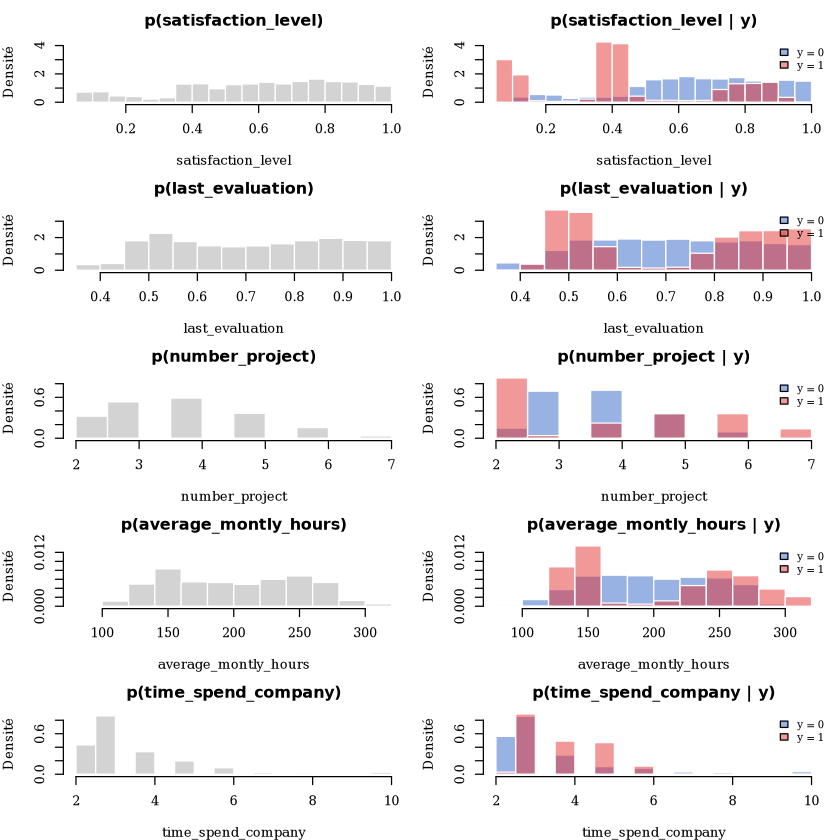

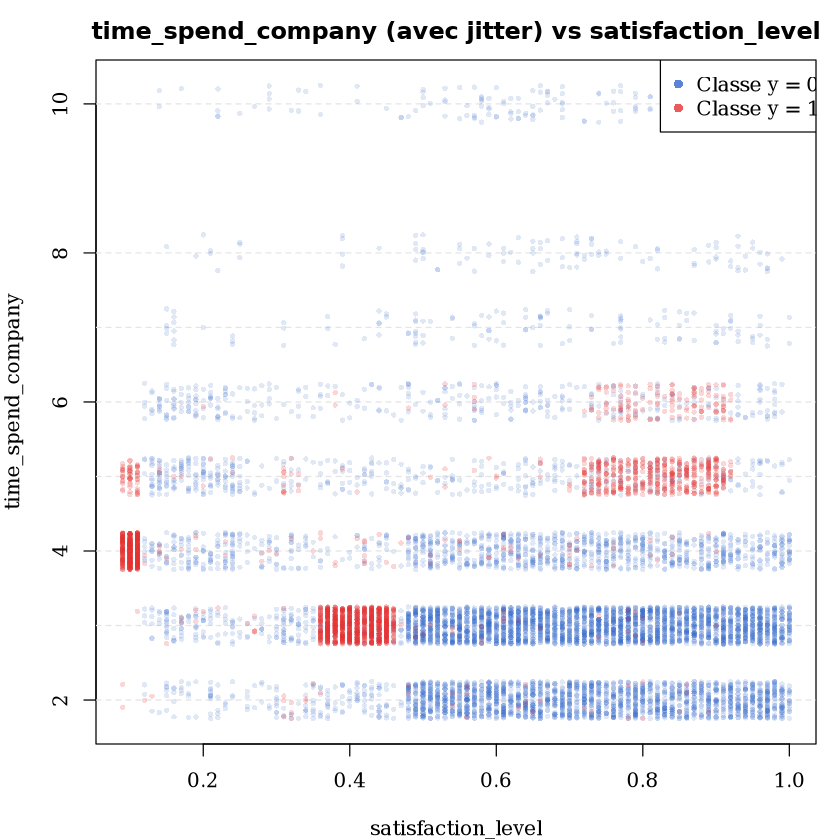

In [5]:
VisualiserDistributions <- function(datasetFile, separator, hasHeader, indexTargetVariable, indexesQuantitativeColumns) {
    data <- readFile(datasetFile, separator, hasHeader)
    classes <- sort(unique(data[, indexTargetVariable]))
    couleurs <- c(rgb(0.2, 0.4, 0.8, 0.5), rgb(0.9, 0.2, 0.2, 0.5), rgb(0.2, 0.8, 0.4, 0.5))

    # Organiser la grille : 1 ligne par attribut, 2 colonnes (p(f) et p(f|y))
    par(mfrow = c(length(indexesQuantitativeColumns), 2), mar = c(4, 4, 2.5, 1))

    for (index in indexesQuantitativeColumns) {
        nomAttr <- names(data)[index]
        valeurs <- data[, index]
        
        # Calcul des bornes (breaks) et du max de densité communs pour aligner les axes
        h_global <- hist(valeurs, plot = FALSE)
        bornes <- h_global$breaks
        max_densite <- max(h_global$density)
        
        for (c in classes) {
            h_cond <- hist(valeurs[data[, indexTargetVariable] == c], breaks = bornes, plot = FALSE)
            max_densite <- max(max_densite, h_cond$density)
        }

        # 1. Graphique de gauche : Distribution marginale p(f)
        hist(valeurs, freq = FALSE, breaks = bornes, ylim = c(0, max_densite),
             col = "lightgray", border = "white",
             main = paste("p(", nomAttr, ")", sep = ""), xlab = nomAttr, ylab = "Densité")

        # 2. Graphique de droite : Distributions conditionnelles p(f | y)
        for (i in seq_along(classes)) {
            c <- classes[i]
            val_cond <- valeurs[data[, indexTargetVariable] == c]
            
            hist(val_cond, freq = FALSE, breaks = bornes, ylim = c(0, max_densite),
                 col = couleurs[i], border = "white", add = (i > 1),
                 main = paste("p(", nomAttr, " | y)", sep = ""), xlab = nomAttr, ylab = "Densité")
        }
        
        legend("topright", legend = paste("y =", classes), fill = couleurs[seq_along(classes)], bty = "n", cex = 0.8)
    }
    
    # Réinitialiser la disposition graphique par défaut
    par(mfrow = c(1, 1))
}

VisualiserDispersion <- function(datasetFile, separator, hasHeader, indexTargetVariable, indexAttr1, indexAttr2) {
    data <- readFile(datasetFile, separator, hasHeader)
    
    nomAttr1 <- names(data)[indexAttr1]
    nomAttr2 <- names(data)[indexAttr2]
    
    classes <- sort(unique(data[, indexTargetVariable]))
    # Opacité très faible (alpha = 0.15) pour voir les zones de forte concentration
    couleurs <- c(rgb(0.2, 0.4, 0.8, 0.15), rgb(0.9, 0.2, 0.2, 0.2))
    symboles <- c(16, 16)
    
    # Ajout d'un léger bruit aléatoire (jitter) sur l'axe Y discret (time_spend_company)
    y_jitter <- jitter(data[, indexAttr2], amount = 0.25)
    
    plot(data[, indexAttr1], y_jitter, type = "n",
         main = paste(nomAttr2, "(avec jitter) vs", nomAttr1),
         xlab = nomAttr1, ylab = nomAttr2)
    
    # Grille horizontale pour bien distinguer chaque année
    abline(h = sort(unique(data[, indexAttr2])), col = "gray90", lty = 2)
    
    for (i in seq_along(classes)) {
        c <- classes[i]
        idx <- which(data[, indexTargetVariable] == c)
        
        points(data[idx, indexAttr1], y_jitter[idx],
               col = couleurs[i], pch = symboles[i], cex = 0.6)
    }
    
    legend("topright", legend = paste("Classe y =", classes),
           col = c(rgb(0.2, 0.4, 0.8, 0.8), rgb(0.9, 0.2, 0.2, 0.8)), 
           pch = 16, bg = "white")
}

VisualiserDistributions("HR_prediction-all.csv", ",", TRUE, 8, c(2, 3, 4, 5, 6))

VisualiserDispersion("HR_prediction-all.csv", ",", TRUE, 8, 2, 6)